In [1]:
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
num_agent = 5
random_seed = 0

num_trained_model = 5
train_seed = 0

In [6]:
model_name = "targetExp225d"

In [7]:
folder = f"NUM_AGENT{str(num_agent).zfill(2)}{model_name}/{str(train_seed).zfill(4)}/"

reward_csv = folder + f"reward_output/reward_history-NUM_AGENT{str(num_agent).zfill(2)}-Random_seed{str(train_seed).zfill(4)}.csv"
distance_csv = folder + f"distance_output/total_distance_list-NUM_AGENT{str(num_agent).zfill(2)}-Random_seed{str(train_seed).zfill(4)}.csv"
trajectory_csv = folder + f"greedy_output/check_position_heading-NUM_AGENT{str(num_agent).zfill(2)}-Random_seed{str(random_seed).zfill(4)}-NUMBER_OF_AGENT_TRAINED_MODEL{str(num_trained_model).zfill(2)}-Random_seed_trained_model{str(train_seed).zfill(4)}.csv"


<AxesSubplot:>

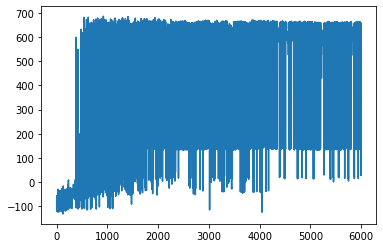

In [8]:
df_reward = pd.read_csv(reward_csv, header=None)
df_reward.loc[0, :].plot()

pygame 2.5.1 (SDL 2.28.2, Python 3.10.1)
Hello from the pygame community. https://www.pygame.org/contribute.html
Fixed initial position
success rate: 0.95
up rate: 0.6526315789473685
low rate: 0.3473684210526316


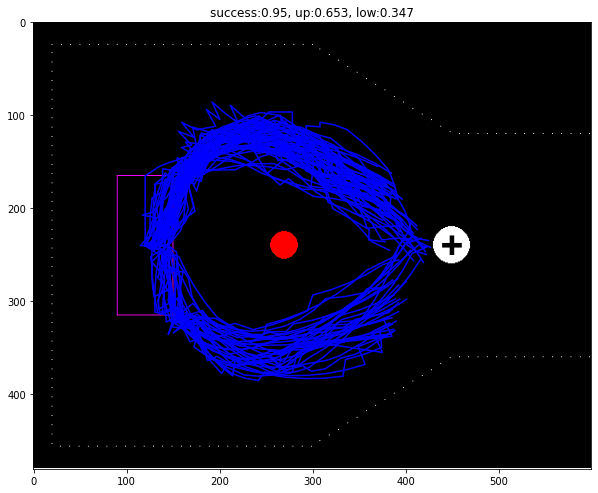

In [9]:
# plot the trajectories of the box with all random seeds
from scripts.pygame_env import CustomEnv
import pygame
import numpy as np

env = CustomEnv(random_initialization=False, n_agents=5)
env.render()

plt.figure(figsize=[10, 10])
background = np.transpose(
        np.array(pygame.surfarray.pixels3d(env.screen)), axes=(1, 0, 2)
    )
plt.imshow(background)

pygame.quit()

count_success = 0
count_up = 0
count_low = 0
total_num = 100

for train_seed in range(total_num):
    folder = f"NUM_AGENT{str(num_agent).zfill(2)}{model_name}/{str(train_seed).zfill(4)}/"
    trajectory_csv = folder + f"greedy_output/check_position_heading-NUM_AGENT{str(num_agent).zfill(2)}-Random_seed{str(random_seed).zfill(4)}-NUMBER_OF_AGENT_TRAINED_MODEL{str(num_trained_model).zfill(2)}-Random_seed_trained_model{str(train_seed).zfill(4)}.csv"
    success_csv = folder + f"greedy_output/check_success-NUM_AGENT{str(num_agent).zfill(2)}-Random_seed{str(random_seed).zfill(4)}-NUMBER_OF_AGENT_TRAINED_MODEL{str(num_trained_model).zfill(2)}-Random_seed_trained_model{str(train_seed).zfill(4)}.csv"
    
    # check success rate
    df_success = pd.read_csv(success_csv, header=None)
    if df_success.loc[0, 0] < 1:
        continue
    count_success += 1
    
    df_trajectory = pd.read_csv(trajectory_csv, header=None)
    x = df_trajectory.loc[:, 1].to_numpy()
    y = df_trajectory.loc[:, 2].to_numpy()
    plt.plot(x, y, "b")
    
    if min(y) > 200:
        count_low += 1
    else:
        count_up += 1
        
print(f"success rate: {count_success/total_num}")
print(f"up rate: {count_up/count_success}")
print(f"low rate: {count_low/count_success}")

plt.title(f"success:{count_success/total_num}, up:{count_up/count_success :.3f}, low:{count_low/count_success :.3f}")
plt.ylim([background.shape[0], 0])
import os
if not os.path.exists("plots"):
    os.makedirs("plots")
plt.savefig(f"plots/NUM_AGENT{str(num_agent).zfill(2)}{model_name}-Random_seed{str(random_seed).zfill(4)}-NUMBER_OF_AGENT_TRAINED_MODEL{str(num_trained_model).zfill(2)}.png",
           facecolor="white")

Fixed initial position


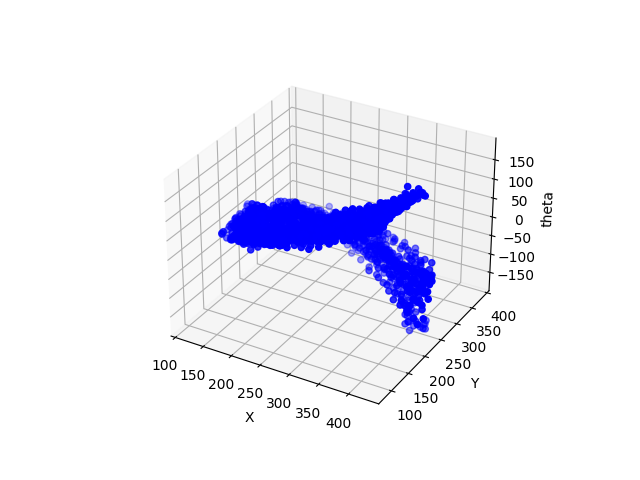

success rate: 1.9
up rate: 0.6526315789473685
low rate: 0.3473684210526316


In [10]:
# plot the trajectories of the box with all random seeds in 3D space
from scripts.pygame_env import CustomEnv
import pygame
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

%matplotlib widget

env = CustomEnv(random_initialization=False, n_agents=5)
env.render()

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# background = np.transpose(
#         np.array(pygame.surfarray.pixels3d(env.screen)), axes=(1, 0, 2)
#     )
# plt.imshow(background)

pygame.quit()

last_x = []
last_y = []
last_theta = []

for train_seed in range(total_num):
    folder = f"NUM_AGENT{str(num_agent).zfill(2)}{model_name}/{str(train_seed).zfill(4)}/"
    trajectory_csv = folder + f"greedy_output/check_position_heading-NUM_AGENT{str(num_agent).zfill(2)}-Random_seed{str(random_seed).zfill(4)}-NUMBER_OF_AGENT_TRAINED_MODEL{str(num_trained_model).zfill(2)}-Random_seed_trained_model{str(train_seed).zfill(4)}.csv"
    success_csv = folder + f"greedy_output/check_success-NUM_AGENT{str(num_agent).zfill(2)}-Random_seed{str(random_seed).zfill(4)}-NUMBER_OF_AGENT_TRAINED_MODEL{str(num_trained_model).zfill(2)}-Random_seed_trained_model{str(train_seed).zfill(4)}.csv"
    
    # check success rate
    df_success = pd.read_csv(success_csv, header=None)
    if df_success.loc[0, 0] < 1:
        continue
    count_success += 1
    
    df_trajectory = pd.read_csv(trajectory_csv, header=None)
    x = df_trajectory.loc[:, 1].to_numpy()
    y = df_trajectory.loc[:, 2].to_numpy()
    theta = df_trajectory.loc[:, 3].to_numpy()
    
    last_x.append(x[-1])
    last_y.append(y[-1])
    last_theta.append(theta[-1])
    
    # Create the 3D scatter plot
    scatter = ax.scatter(x, y, theta, c='b', marker='o')
    
    if min(y) > 200:
        count_low += 1
    else:
        count_up += 1
       
# Set labels
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('theta')

plt.show()
    
print(f"success rate: {count_success/total_num}")
print(f"up rate: {count_up/count_success}")
print(f"low rate: {count_low/count_success}")

# plt.title(f"success:{count_success/total_num}, up:{count_up/count_success :.3f}, low:{count_low/count_success :.3f}")
# plt.ylim([background.shape[0], 0])
# import os
# if not os.path.exists("plots"):
#     os.makedirs("plots")
# plt.savefig(f"plots/NUM_AGENT{str(num_agent).zfill(2)}{model_name}-Random_seed{str(random_seed).zfill(4)}-NUMBER_OF_AGENT_TRAINED_MODEL{str(num_trained_model).zfill(2)}.png",
#            facecolor="white")

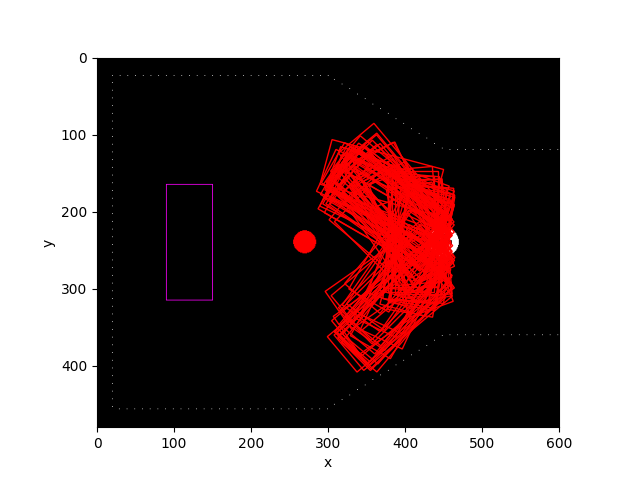

In [11]:
import matplotlib.patches as patches
from scripts import constant

fig, ax = plt.subplots()
ax.imshow(background)

def draw_rec(last_x, last_y, last_theta):
    w = constant.box_width
    h = constant.box_height
    
    origin_vertices = np.array([[-w/2, -h/2],
                                [-w/2, h/2],
                                [w/2, h/2],
                                [w/2, -h/2]]).T
    
    for i in range(len(last_x)):
        x, y, theta = last_x[i], last_y[i], last_theta[i]*np.pi/180
        rotation_mat = np.array([[np.cos(theta), -np.sin(theta)],
                                 [np.sin(theta), np.cos(theta)]])
        vertices = rotation_mat.dot(origin_vertices).T
        vertices[:, 0] += x
        vertices[:, 1] += y
        
        rect = patches.Polygon(vertices, color="r", fill=False)
        ax.add_patch(rect)
#         break
        
draw_rec(last_x, last_y, last_theta)
plt.xlim([0, 600])
plt.ylim([480, 0])
plt.xlabel("x")
plt.ylabel("y")

plt.show()

plt.savefig(f"plots/NUM_AGENT{str(num_agent).zfill(2)}{model_name}-Random_seed{str(random_seed).zfill(4)}-NUMBER_OF_AGENT_TRAINED_MODEL{str(num_trained_model).zfill(2)}_lastState.png",
           facecolor="white")

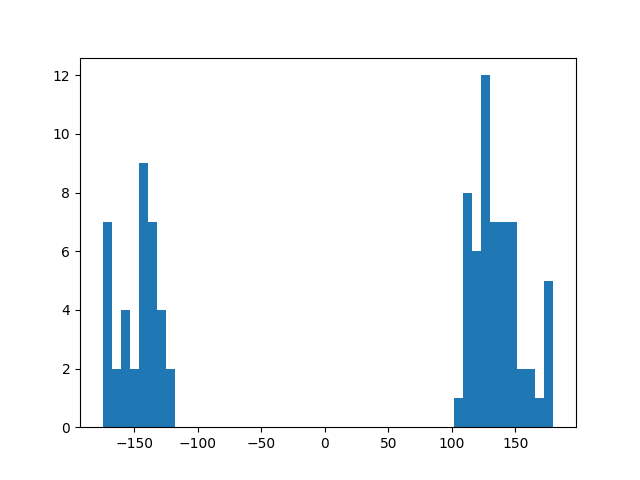

Text(0.5, 1.0, 'histogram of final theta, target angle')

In [19]:
target_theta1 = 225
target_theta2 = np.mod(target_theta1 + 180, 360)

plt.figure()
plt.hist(last_theta, bins=50)
plt.show()
plt.title("histogram of final theta, target angle")

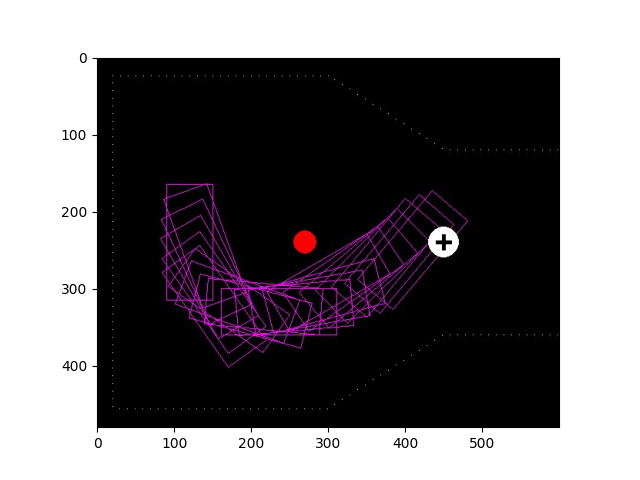

In [30]:
seed = 33
plt.figure()
img = plt.imread(f"NUM_AGENT{str(num_agent).zfill(2)}{model_name}/{str(seed).zfill(4)}/screenshot/screenshot{str(seed).zfill(4)}.jpg")
plt.imshow(img)

In [39]:
last_theta[0]

-115.0000000000001

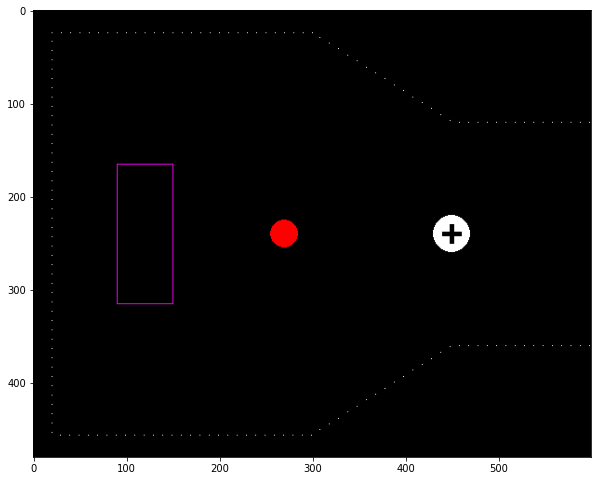

In [59]:
from scripts.pygame_env import CustomEnv
import pygame

env = CustomEnv(random_initialization=False, n_agents=5)
env.render()

plt.figure(figsize=[10, 10])
plt.imshow(np.transpose(
        np.array(pygame.surfarray.pixels3d(env.screen)), axes=(1, 0, 2)
    ))

pygame.quit()
# cv2.imwrite("test.png", np.transpose(
#         np.array(pygame.surfarray.pixels3d(env.screen)), axes=(1, 0, 2)
#     ))